=== Вагові коефіцієнти ФВЧ (Програмний розрахунок) ===
a_0 = -0.1215
a_1 = -0.1307
a_2 = 0.9816
a_3 = -0.1307
a_4 = -0.1215
=== Вагові коефіцієнти ФВЧ (Власна реалізація за формулою методички) ===
a_0 = 0.8800
a_1 = -0.1172
a_2 = -0.1089
a_3 = -0.0960
a_4 = -0.0794




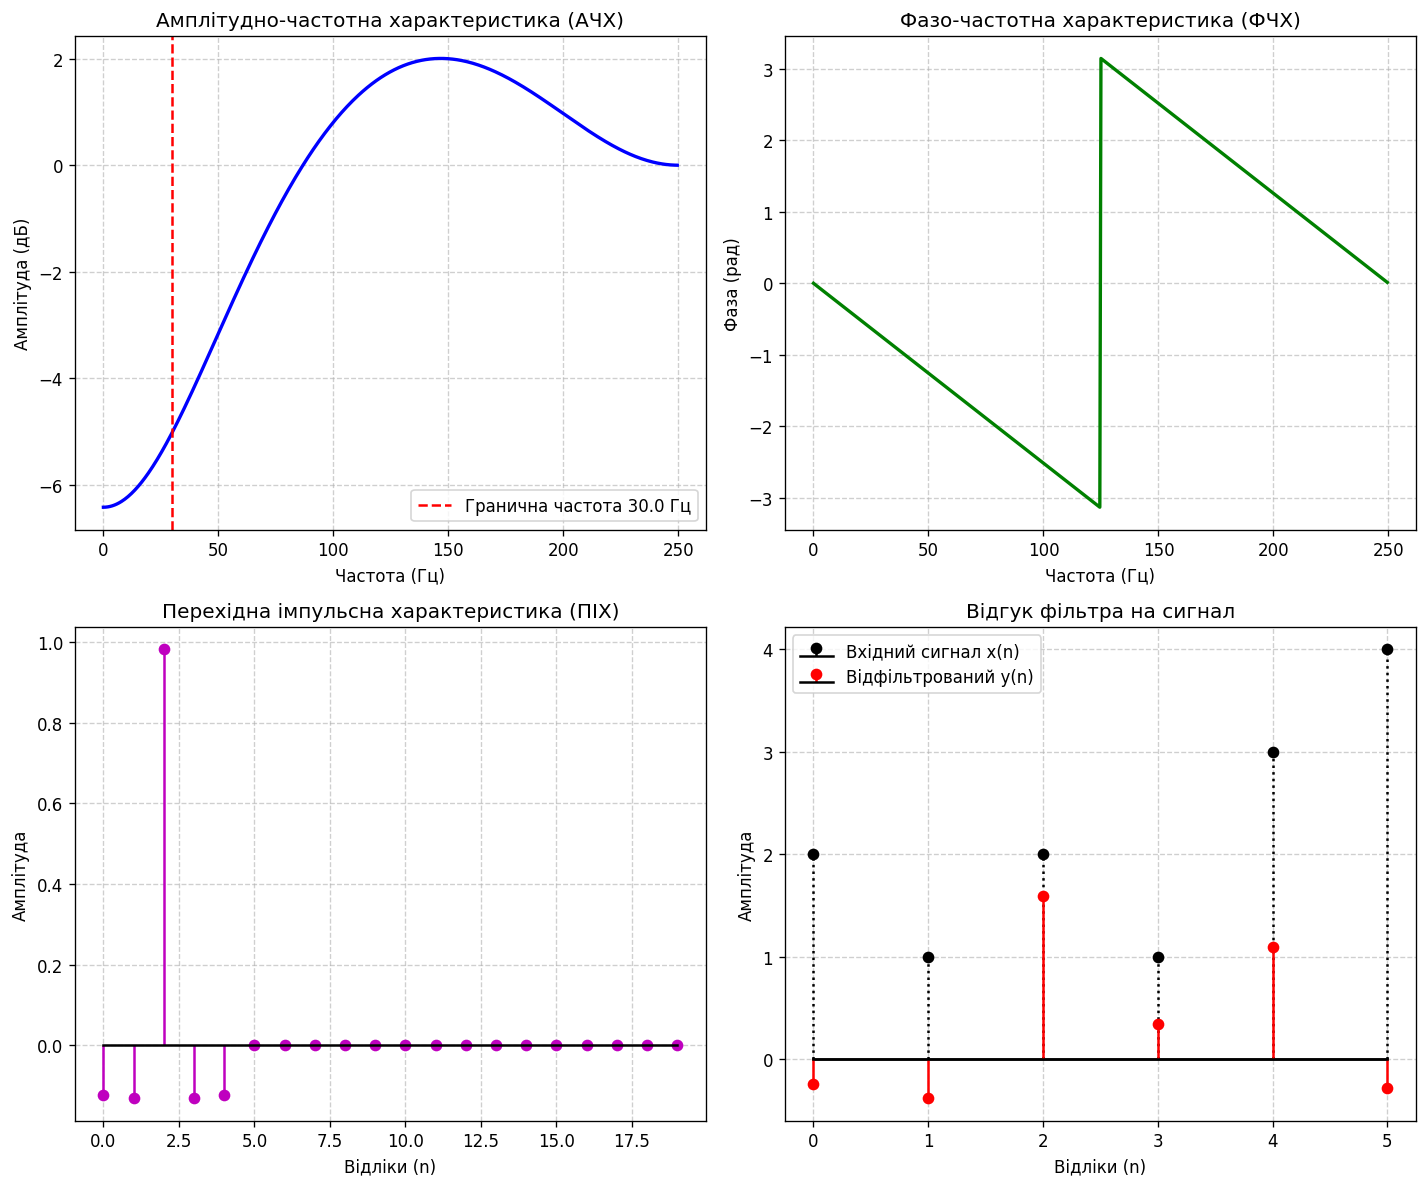

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import firwin, freqz, lfilter, unit_impulse

# 1. ПАРАМЕТРИ ФІЛЬТРА (Варіант 5)
# ==============================================================================
N = 4                    # Порядок фільтра
numtaps = N + 1          # Кількість вагових коефіцієнтів
fg = 30.0                # Гранична частота (Гц)
fa = 500.0               # Частота дискретизації (Гц)

# Вхідний сигнал з Лабораторної №2
x_n = np.array([2.0, 1.0, 2.0, 1.0, 3.0, 4.0])

# 2. ПРОЕКТУВАННЯ ФІЛЬТРА ФВЧ (Аналог fir1 у Matlab)
# ==============================================================================
# pass_zero=False вказує, що нульові частоти не пропускаються (це ФВЧ)
b = firwin(numtaps, fg, pass_zero=False, fs=fa, window='boxcar')

print("=== Вагові коефіцієнти ФВЧ (Програмний розрахунок) ===")
for k, coef in enumerate(b):
    print(f"a_{k} = {coef:.4f}")

# ==============================================================================
# 3. РУЧНИЙ РОЗРАХУНОК (Несиметричний ФВЧ за методичкою)
# ==============================================================================
a_manual = np.zeros(numtaps)

# Коефіцієнт k = 0 (Постійна складова)
a_lpf_0 = 2 * (fg / fa)
a_manual[0] = 1 - a_lpf_0  # Перехід від ФНЧ до ФВЧ

# Коефіцієнти k = 1..4
for k in range(1, numtaps):
    arg = 2 * np.pi * k * (fg / fa)
    # Формула (7) для ФНЧ
    a_lpf_k = 2 * fg * np.sin(arg) / (fa * arg)
    # Перехід до ФВЧ (a_ВФ = 0 для k > 0)
    a_manual[k] = 0 - a_lpf_k

print("=== Вагові коефіцієнти ФВЧ (Власна реалізація за формулою методички) ===")
for k, coef in enumerate(a_manual):
    print(f"a_{k} = {coef:.4f}")
print("\n")

# 4. АНАЛІЗ ХАРАКТЕРИСТИК ФІЛЬТРА
# ==============================================================================
# Частотний відгук (АЧХ та ФЧХ) - аналог freqz
w, h = freqz(b, worN=512, fs=fa)
magnitude = 20 * np.log10(np.abs(h))  # АЧХ у децибелах
phase = np.angle(h)                   # ФЧХ у радіанах

# Перехідна імпульсна характеристика (ПІХ) - аналог impz
impulse = unit_impulse(20)            # Одиничний імпульс (дельта-функція)
h_impulse = lfilter(b, 1.0, impulse)  # Відгук фільтра на імпульс

# ==============================================================================
# 5. ФІЛЬТРАЦІЯ ВХІДНОГО СИГНАЛУ
# ==============================================================================
y_n = lfilter(b, 1.0, x_n)


# ==============================================================================
# 6. ВІЗУАЛІЗАЦІЯ
# ==============================================================================
fig = plt.figure(figsize=(12, 10), dpi=120)

# 1. Амплітудно-частотна характеристика (АЧХ)
ax1 = plt.subplot(2, 2, 1)
ax1.plot(w, magnitude, 'b-', linewidth=2)
ax1.set_title('Амплітудно-частотна характеристика (АЧХ)')
ax1.set_xlabel('Частота (Гц)')
ax1.set_ylabel('Амплітуда (дБ)')
ax1.axvline(fg, color='r', linestyle='--', label=f'Гранична частота {fg} Гц')
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.legend()

# 2. Фазо-частотна характеристика (ФЧХ)
ax2 = plt.subplot(2, 2, 2)
ax2.plot(w, phase, 'g-', linewidth=2)
ax2.set_title('Фазо-частотна характеристика (ФЧХ)')
ax2.set_xlabel('Частота (Гц)')
ax2.set_ylabel('Фаза (рад)')
ax2.grid(True, linestyle='--', alpha=0.6)

# 3. Перехідна імпульсна характеристика (ПІХ)
ax3 = plt.subplot(2, 2, 3)
ax3.stem(range(20), h_impulse, linefmt='m-', markerfmt='mo', basefmt='k-')
ax3.set_title('Перехідна імпульсна характеристика (ПІХ)')
ax3.set_xlabel('Відліки (n)')
ax3.set_ylabel('Амплітуда')
ax3.grid(True, linestyle='--', alpha=0.6)

# 4. Результат фільтрації
ax4 = plt.subplot(2, 2, 4)
ax4.stem(range(len(x_n)), x_n, linefmt='k:', markerfmt='ko', basefmt='k-', label='Вхідний сигнал x(n)')
ax4.stem(range(len(y_n)), y_n, linefmt='r-', markerfmt='ro', basefmt='k-', label='Відфільтрований y(n)')
ax4.set_title('Відгук фільтра на сигнал')
ax4.set_xlabel('Відліки (n)')
ax4.set_ylabel('Амплітуда')
ax4.grid(True, linestyle='--', alpha=0.6)
ax4.legend()

plt.tight_layout()
plt.savefig('lab4_filter_characteristics.png', dpi=300)
plt.show()